In [5]:
import polars as pl

uri='postgresql://blue:5432/lottery?options=-c%20synchronous_commit%3Doff%20-c%20session_replication_role%3Dreplica%20-c%20work_mem%3D1GB%20-c%20maintenance_work_mem%3D2GB%20-c%20temp_buffers%3D2GB%20-c%20max_parallel_workers_per_gather%3D4'
query='SELECT ttl_cnt,ttl_reward::numeric::BIGINT FROM data_source ORDER BY ttl_reward DESC '

df=pl.read_database_uri(uri=uri,query=query)

<Axes: xlabel='ttl_cnt', ylabel='ttl_reward'>

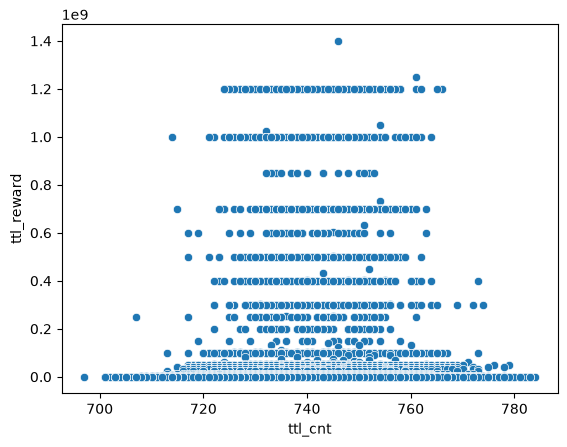

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(x=df['ttl_cnt'],y=df['ttl_reward'])

In [8]:
print(
    df.select(
        pl.corr("ttl_cnt", "ttl_reward", method="pearson")
          .alias("pearson"),
        pl.corr("ttl_cnt", "ttl_reward", method="spearman")
          .alias("spearman"),
    )
)

shape: (1, 2)
┌──────────┬──────────┐
│ pearson  ┆ spearman │
│ ---      ┆ ---      │
│ f64      ┆ f64      │
╞══════════╪══════════╡
│ 0.012689 ┆ 0.580476 │
└──────────┴──────────┘
